# 07. Холодный старт: качество от числа оценок пользователя (E2)

Контекст — `решения.md`: 3.7 (E2), 3.3 (веса формулы гибрида от числа оценок), 3.2 (модели и параметры из E1).

- **Данные — как в 06:** подвыборка 20% пользователей (seed 42), обучение до 2021, проверка — валидация (2021).
- **Способ — усечение истории** (`ml/src/eval/coldstart.py`): берутся пользователи с ≥ 20 оценками в обучении, их история
  обрезается до N последних оценок (N = 1 / 3 / 5 / 10 / 20 и вся история); остальные пользователи — с полной историей.
  При каждом N — **одни и те же люди**, меняется только длина истории. Корзины по фактическому числу оценок смешали бы
  длину истории с тем, кто эти люди (у кого 1 оценка, а у кого 50, — разные читатели).
- **Модели:** Popularity, Content TF-IDF, Content e5-base, ItemKNN и ALS с лучшими параметрами E1 (`models/optuna/cf.db`).
  Коллаборативные модели переобучаются при каждом N: усечённые пользователи меняют матрицу оценок.
- **Два каталога для content-моделей** (06, раздел 5): **«известные на дату»** — книги с первой оценкой в полных данных
  до 01.01.2021, основной режим; **«весь каталог»** — как в E1, завышен: в нём есть книги, впервые оценённые после даты
  разбиения, — они «знают», что их оценят. Коллаборативные модели выбирают только из книг обучения, каталог их не касается.
- **Правило кандидатов** (как в 06 и 08): ни одна модель не рекомендует книги с 1–4 оценками в обучении (`eval.data.drop_rare`,
  по полному обучению — одинаково при любом N): они попали в подвыборку благодаря будущим оценкам.
- **Метрика:** NDCG@10 «все / старые / новые» с 95% ДИ (bootstrap по пользователям); сравнения — парный bootstrap.

In [1]:
import os
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")

import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
from rectools import Columns
from rectools.models import PopularModel

warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path.cwd().parent / "src"))
from cf.models import SEED, fit_recommend
from cf.tune import STORAGE, best_params
from content.embeddings import catalog, load_books
from content.recommend import recommend, tfidf_vectors
from eval.coldstart import cohort, truncate_history
from eval.data import VAL_START, drop_rare, first_seen, known_at, load_ratings, subsample_users, time_split, to_dataset
from eval.metrics import K, bootstrap_ci, eval_users, evaluate, paired_bootstrap, with_ci
from eval.search import informative

REPORTS = Path.cwd().parent / "reports"
K_GEN = K + 20   # запас под правило кандидатов
pd.options.display.float_format = "{:.4f}".format

ratings = load_ratings()
first = first_seen(ratings)
sub = subsample_users(ratings, 0.2, seed=SEED)
train, val, test = time_split(sub)

books = load_books(["parent_asin", "text", "features", "categories"])
ids_all = books["parent_asin"].to_numpy()
allowed_all = informative(books)
CATALOGS = {"известные": allowed_all & known_at(ids_all, first, VAL_START), "весь": allowed_all}
print("книг в каталоге: " + ", ".join(f"{c} — {m.sum():,}" for c, m in CATALOGS.items()))
X_tfidf, _ = tfidf_vectors(books["text"])
E5 = np.asarray(catalog("e5-base"))

optuna.logging.set_verbosity(optuna.logging.WARNING)
BEST = {k: best_params(optuna.load_study(study_name=k, storage=f"sqlite:///{STORAGE}")) for k in ["knn", "als"]}

MAX_N = 20
LEVELS = [1, 3, 5, 10, 20, None]
LABEL = {n: "вся" if n is None else str(n) for n in LEVELS}
users = cohort(train, val, MAX_N)
n_eval = len(eval_users(train, val))
counts = train[Columns.User].astype(str).value_counts().reindex(users)
print(f"Пользователей с ≥ {MAX_N} оценками в обучении: {len(users):,} из {n_eval:,} проверяемых ({len(users) / n_eval:.0%}); "
      f"оценок в обучении у них — медиана {counts.median():.0f}")

книг в каталоге: известные — 376,233, весь — 405,555


Пользователей с ≥ 20 оценками в обучении: 2,479 из 21,350 проверяемых (12%); оценок в обучении у них — медиана 32


## 1. Прогон: модели × 6 длин истории

In [2]:
def rule(reco):
    return drop_rare(reco, train, k=K)   # по полному обучению — набор книг не зависит от N

def popular(tr, us):
    ds = to_dataset(tr, weighted=False)
    m = PopularModel(popularity="n_users").fit(ds)
    return rule(m.recommend(us, ds, k=K_GEN, filter_viewed=True, on_unsupported_targets="ignore"))

def content(vectors, cat):
    return lambda tr, us: rule(recommend(vectors, ids_all, tr, us, k=K_GEN, allowed=CATALOGS[cat]))

CF = {"Popularity": popular,
      "ItemKNN": lambda tr, us: rule(fit_recommend("knn", BEST["knn"], tr, us, k=K_GEN)[0]),
      "ALS": lambda tr, us: rule(fit_recommend("als", BEST["als"], tr, us, k=K_GEN)[0])}
CONTENT = {(name, cat): content(v, cat) for cat in CATALOGS for name, v in [("Content TF-IDF", X_tfidf), ("Content e5-base", E5)]}
MODELS = {**{(name, "—"): f for name, f in CF.items()}, **CONTENT}

rows, per_user = [], {}
t_all = time.time()
for n in LEVELS:
    tr = truncate_history(train, users, n)
    for (name, cat), make in MODELS.items():
        t0 = time.time()
        table, pu = evaluate(make(tr, users), tr, val, users)
        per_user[(n, name, cat)] = pu
        rows.append(with_ci(table, pu).assign(модель=name, каталог=cat, N=LABEL[n], секунд=round(time.time() - t0, 1)))
    print(f"N = {LABEL[n]}: готово, {time.time() - t_all:.0f} с с начала")

res = pd.concat(rows, ignore_index=True)
cols = ["N", "модель", "каталог", "разрез", "пользователей", "NDCG@10", "NDCG@10 95% ДИ", "Recall@10", "Coverage@10", "секунд"]
res = res[cols]
res.to_csv(REPORTS / "metrics" / "coldstart_val.csv", index=False, encoding="utf-8")

def model_label(name, cat):
    return name if cat == "—" else f"{name} · {cat}"

res["модель, каталог"] = [model_label(m, c) for m, c in zip(res["модель"], res["каталог"])]
order = [model_label(*key) for key in MODELS]
for s in ["все", "старые", "новые"]:
    print(f"\nNDCG@10, разрез «{s}»:")
    display(res[res["разрез"] == s].pivot_table(index="N", columns="модель, каталог", values="NDCG@10", sort=False)[order])

N = 1: готово, 126 с с начала


N = 3: готово, 247 с с начала


N = 5: готово, 368 с с начала


N = 10: готово, 501 с с начала


N = 20: готово, 637 с с начала


N = вся: готово, 763 с с начала

NDCG@10, разрез «все»:


"модель, каталог",Popularity,ItemKNN,ALS,Content TF-IDF · известные,Content e5-base · известные,Content TF-IDF · весь,Content e5-base · весь
N,,,,,,,
1,0.0024,0.0097,0.0084,0.0051,0.0045,0.0152,0.0154
3,0.0024,0.0135,0.0099,0.0063,0.0076,0.0196,0.0200
5,0.0024,0.0160,0.0113,0.0066,0.0071,0.0202,0.0184
10,0.0025,0.0172,0.0119,0.0050,0.0044,0.0154,0.0123
20,0.0025,0.0165,0.0107,0.0034,0.0036,0.0087,0.0078
вся,0.0027,0.0128,0.0098,0.0012,0.0021,0.0053,0.0048



NDCG@10, разрез «старые»:


"модель, каталог",Popularity,ItemKNN,ALS,Content TF-IDF · известные,Content e5-base · известные,Content TF-IDF · весь,Content e5-base · весь
N,,,,,,,
1,0.0034,0.0145,0.0120,0.0071,0.0063,0.0064,0.0054
3,0.0034,0.0206,0.0146,0.0098,0.0114,0.0083,0.0098
5,0.0034,0.0248,0.0169,0.0104,0.0111,0.0082,0.0095
10,0.0035,0.0274,0.0177,0.0073,0.0073,0.0067,0.0056
20,0.0036,0.0250,0.0155,0.0047,0.0060,0.0041,0.0045
вся,0.0039,0.0188,0.0140,0.0016,0.0033,0.0015,0.0026



NDCG@10, разрез «новые»:


"модель, каталог",Popularity,ItemKNN,ALS,Content TF-IDF · известные,Content e5-base · известные,Content TF-IDF · весь,Content e5-base · весь
N,,,,,,,
1,0.0000,0.0000,0.0000,0.0001,0.0002,0.0196,0.0221
3,0.0000,0.0000,0.0000,0.0001,0.0001,0.0280,0.0262
5,0.0000,0.0000,0.0000,0.0001,0.0001,0.0287,0.0244
10,0.0000,0.0000,0.0000,0.0000,0.0000,0.0208,0.0169
20,0.0000,0.0000,0.0000,0.0002,0.0000,0.0110,0.0097
вся,0.0000,0.0000,0.0000,0.0000,0.0000,0.0077,0.0059


## 2. Графики

Рисунки для диплома: NDCG@10 на валидации в зависимости от числа последних оценок пользователя; полосы — 95% ДИ.
Основной — каталог «известные на дату» (`09_cold_start_ndcg_known.png`); «весь каталог» (`09_cold_start_ndcg.png`) —
для сравнения, content в нём завышен.

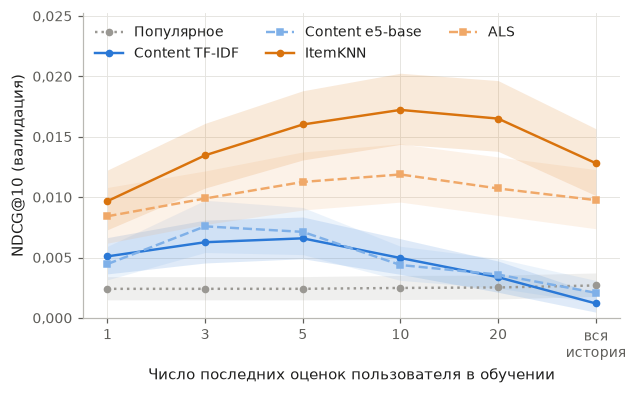

→ ml/reports/figures/09_cold_start_ndcg_known.png


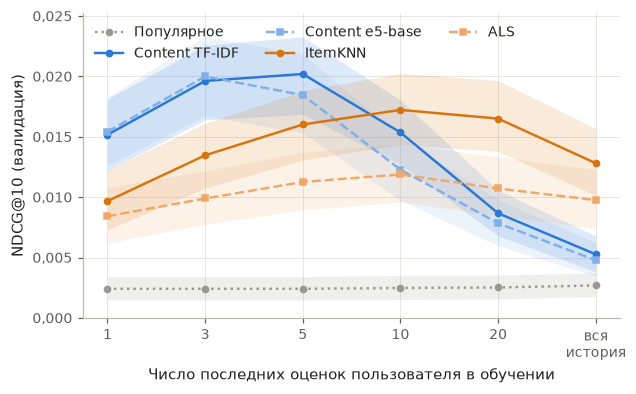

→ ml/reports/figures/09_cold_start_ndcg.png


In [3]:
BLUE, INK, MUTED, GRID = "#2a78d6", "#1f1f1e", "#5f5e5a", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "font.size": 10, "axes.labelsize": 10, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "text.color": INK, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.edgecolor": "#b9b8b3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
})
W = 6.3
STYLE = {  # content — синие, коллаборативные — оранжевые, популярность — серая
    "Popularity": dict(color="#9a9893", ls=":", marker="o", label="Популярное"),
    "Content TF-IDF": dict(color=BLUE, ls="-", marker="o", label="Content TF-IDF"),
    "Content e5-base": dict(color="#7fb0e8", ls="--", marker="s", label="Content e5-base"),
    "ItemKNN": dict(color="#d9730d", ls="-", marker="o", label="ItemKNN"),
    "ALS": dict(color="#f0a868", ls="--", marker="s", label="ALS"),
}

def plot(cat, filename, ymax=None):
    fig, ax = plt.subplots(figsize=(W, 3.6))
    x = np.arange(len(LEVELS))
    for name, st in STYLE.items():
        key_cat = "—" if name in CF else cat
        y = [per_user[(n, name, key_cat)]["все"].mean() for n in LEVELS]
        ci = np.array([bootstrap_ci(per_user[(n, name, key_cat)]["все"]) for n in LEVELS])
        ax.fill_between(x, ci[:, 0], ci[:, 1], color=st["color"], alpha=0.15, lw=0)
        ax.plot(x, y, lw=1.6, ms=4, **st)
    ax.set_xticks(x, [LABEL[n] if n else "вся\nистория" for n in LEVELS])
    ax.set_xlabel("Число последних оценок пользователя в обучении")
    ax.set_ylabel("NDCG@10 (валидация)")
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:.3f}".replace(".", ","))
    ax.set_ylim(0, ymax)
    ax.legend(frameon=False, ncol=3, loc="upper left", fontsize=9)
    fig.savefig(REPORTS / "figures" / filename)
    plt.show()
    print(f"→ ml/reports/figures/{filename}")

ymax = res.loc[res["разрез"] == "все", "NDCG@10"].max() * 1.25   # одна шкала на обоих рисунках
plot("известные", "09_cold_start_ndcg_known.png", ymax)
plot("весь", "09_cold_start_ndcg.png", ymax)

**Главное (2 479 пользователей с ≥ 20 оценками, одни и те же при каждом N; правило кандидатов — во всех моделях):**
- **Каталог «известные на дату» (основной): ItemKNN лучше content при любом N, даже при одной оценке** — 0,0097 против
  0,0051 (TF-IDF) и 0,0045 (e5-base); при N = 10 — 0,0172 против 0,0050 и 0,0044. Popularity — 0,0024–0,0027, ALS между
  ItemKNN и content (0,0084–0,0119).
- **На «весь каталог» картина обратная** (content 0,015–0,020 при N ≤ 5 — выше ItemKNN), но это утечка каталога: почти все
  «новые» попадания content — книги, впервые оценённые после 01.01.2021 (06, раздел 5). На «известных» у content на
  «новых» ≈ 0 (≤ 0,0002).
- **Content в обоих каталогах лучше всего на 3–5 последних оценках** (e5-base 0,0076 при N = 3, TF-IDF 0,0066 при N = 5) и
  проседает к всей истории (0,0021 и 0,0012): профиль-среднее длинной истории размыт, следующую книгу лучше
  предсказывают последние (серии, тот же автор). Этот вывод от каталога не зависит.
- **ItemKNN растёт до N = 10** (0,0097 → 0,0172) и дальше слегка падает (вся история — 0,0128) — ему тоже полезнее
  недавние оценки. ALS — так же, но ниже (0,0084 → 0,0119).
- Ограничение: усечённому пользователю могут порекомендовать книгу, которую он оценил раньше усечённой истории (она не
  попадание) — это немного занижает усечённые варианты, вывод от этого только консервативнее.

## 3. С какого N коллаборативная часть обгоняет content

In [4]:
sig = []
for cat in CATALOGS:
    for n in LEVELS:
        for a, b in [("ItemKNN", "Content TF-IDF"), ("ALS", "Content TF-IDF"), ("ItemKNN", "Content e5-base"), ("ItemKNN", "ALS")]:
            for s in ["все", "старые"]:
                ka, kb = [(m, "—" if m in CF else cat) for m in (a, b)]
                r = paired_bootstrap(per_user[(n, *ka)][s], per_user[(n, *kb)][s])
                sig.append({"каталог": cat, "N": LABEL[n], "сравнение": f"{a} − {b}", "разрез": s,
                            "разница NDCG@10": r["разница"], "95% ДИ": f"{r['low']:+.4f} … {r['high']:+.4f}",
                            "значимо": ("да, +" if r["low"] > 0 else "да, −") if r["low"] > 0 or r["high"] < 0 else "нет"})
sig = pd.DataFrame(sig)
for cat in CATALOGS:
    print(f"Каталог «{cat}», разрез «все»:")
    display(sig[(sig["каталог"] == cat) & (sig["разрез"] == "все")]
            .pivot_table(index="сравнение", columns="N", values="значимо", aggfunc="first", sort=False)[[LABEL[n] for n in LEVELS]])
sig.style.format({"разница NDCG@10": "{:+.4f}"}).hide(axis="index")

Каталог «известные», разрез «все»:


N,1,3,5,10,20,вся
сравнение,,,,,,
ItemKNN − Content TF-IDF,"да, +","да, +","да, +","да, +","да, +","да, +"
ALS − Content TF-IDF,"да, +","да, +","да, +","да, +","да, +","да, +"
ItemKNN − Content e5-base,"да, +","да, +","да, +","да, +","да, +","да, +"
ItemKNN − ALS,нет,"да, +","да, +","да, +","да, +","да, +"


Каталог «весь», разрез «все»:


N,1,3,5,10,20,вся
сравнение,,,,,,
ItemKNN − Content TF-IDF,"да, −","да, −","да, −",нет,"да, +","да, +"
ALS − Content TF-IDF,"да, −","да, −","да, −",нет,нет,"да, +"
ItemKNN − Content e5-base,"да, −","да, −",нет,"да, +","да, +","да, +"
ItemKNN − ALS,нет,"да, +","да, +","да, +","да, +","да, +"


каталог,N,сравнение,разрез,разница NDCG@10,95% ДИ,значимо
известные,1,ItemKNN − Content TF-IDF,все,+0.0046,+0.0024 … +0.0068,"да, +"
известные,1,ItemKNN − Content TF-IDF,старые,+0.0074,+0.0040 … +0.0109,"да, +"
известные,1,ALS − Content TF-IDF,все,+0.0033,+0.0010 … +0.0058,"да, +"
известные,1,ALS − Content TF-IDF,старые,+0.0049,+0.0014 … +0.0085,"да, +"
известные,1,ItemKNN − Content e5-base,все,+0.0052,+0.0030 … +0.0075,"да, +"
известные,1,ItemKNN − Content e5-base,старые,+0.0082,+0.0052 … +0.0117,"да, +"
известные,1,ItemKNN − ALS,все,+0.0013,-0.0013 … +0.0039,нет
известные,1,ItemKNN − ALS,старые,+0.0025,-0.0010 … +0.0062,нет
известные,3,ItemKNN − Content TF-IDF,все,+0.0072,+0.0045 … +0.0097,"да, +"
известные,3,ItemKNN − Content TF-IDF,старые,+0.0108,+0.0071 … +0.0145,"да, +"


**С какого N коллаборативная часть обгоняет content (разрез «все»):**
- **«Известные на дату»: с первой оценки.** ItemKNN значимо лучше и TF-IDF, и e5-base при каждом N (при N = 1: +0,0046
  [+0,0024; +0,0068] к TF-IDF, +0,0052 [+0,0030; +0,0075] к e5-base); ALS значимо лучше TF-IDF при каждом N. Точки
  пересечения нет.
- **«Весь каталог» (завышен):** при N ≤ 5 content значимо лучше, при N = 10 — ничья с TF-IDF, с N = 20 ItemKNN лучше. Это и
  был вывод первого прогона E2 — он держался на книгах из будущего.
- ItemKNN значимо лучше ALS при любом N ≥ 3 (при N = 1 — незначимо, +0,0013 [−0,0013; +0,0039]).

**Для 3.3:** на нынешних данных у content нет корзины, где он сильнее ItemKNN, поэтому веса формулы — не «content для
новичков», а подбор на валидации (E3: ItemKNN главный во всех корзинах); content остаётся в гибриде ради новых книг,
которые офлайн не измерить.

In [5]:
res.pivot_table(index="модель, каталог", columns="N", values="секунд", aggfunc="sum", sort=False).loc[order, [LABEL[n] for n in LEVELS]]

N,1,3,5,10,20,вся
"модель, каталог",,,,,,
Popularity,6.6000,6.0000,6.0000,6.0000,7.2000,8.7000
ItemKNN,16.5000,13.5000,13.5000,14.7000,20.1000,18.6000
ALS,63.9000,64.5000,59.7000,60.9000,68.7000,64.5000
Content TF-IDF · известные,125.1000,123.6000,124.5000,124.8000,126.3000,126.6000
Content e5-base · известные,21.0000,16.2000,17.1000,18.0000,25.2000,17.4000
Content TF-IDF · весь,123.6000,123.3000,123.6000,156.3000,126.9000,125.4000
Content e5-base · весь,20.1000,16.2000,15.9000,19.2000,32.1000,17.7000


## 4. Проверка: профиль content-модели по последним N оценкам — на всех пользователях

Если content-моделям вредит длинная история, профиль стоит строить по последним оценкам у всех. Проверка — на всех
21 тыс. проверяемых пользователях (как в E1): профиль — из последних N оценок (у кого меньше N — из всех), исключаются
**все** оценённые книги, модели и разрезы «старые / новые» — по полному обучению. e5-base — при всех N, TF-IDF (5 мин на
прогон) — при 5 и полной истории; оба каталога.

In [6]:
users_all = eval_users(train, val)
PROFILE = {"Content e5-base": (E5, LEVELS), "Content TF-IDF": (X_tfidf, [5, None])}
rows4, pu4 = [], {}
for cat, allowed in CATALOGS.items():
    for name, (vectors, levels) in PROFILE.items():
        for n in levels:
            t0 = time.time()
            reco = rule(recommend(vectors, ids_all, train, users_all, k=K_GEN, allowed=allowed,
                                  profile_from=truncate_history(train, users_all, n)))
            table, pu = evaluate(reco, train, val, users_all)
            pu4[(cat, n, name)] = pu
            rows4.append(with_ci(table, pu).assign(модель=name, каталог=cat, N=LABEL[n], секунд=round(time.time() - t0, 1)))
res4 = pd.concat(rows4, ignore_index=True)[[c for c in cols if c != "модель, каталог"]]
res4.to_csv(REPORTS / "metrics" / "coldstart_profile_val.csv", index=False, encoding="utf-8")
display(res4.pivot_table(index=["каталог", "модель", "N"], columns="разрез", values="NDCG@10", sort=False)[["все", "старые", "новые"]])

sig4 = []
for cat in CATALOGS:
    for name in PROFILE:
        for s in ["все", "старые", "новые"]:
            r = paired_bootstrap(pu4[(cat, 5, name)][s], pu4[(cat, None, name)][s])
            sig4.append({"каталог": cat, "модель": name, "разрез": s, "N=5 − вся история": r["разница"],
                         "95% ДИ": f"{r['low']:+.4f} … {r['high']:+.4f}", "значимо": "да" if r["low"] > 0 or r["high"] < 0 else "нет"})
pd.DataFrame(sig4).style.format({"N=5 − вся история": "{:+.4f}"}).hide(axis="index")

разрез                           все  старые  новые
каталог   модель          N                        
известные Content e5-base 1   0.0055  0.0080 0.0003
                          3   0.0052  0.0076 0.0004
                          5   0.0048  0.0070 0.0003
                          10  0.0041  0.0061 0.0001
                          20  0.0039  0.0059 0.0001
                          вся 0.0038  0.0055 0.0001
          Content TF-IDF  5   0.0054  0.0079 0.0003
                          вся 0.0042  0.0060 0.0002
весь      Content e5-base 1   0.0150  0.0072 0.0260
                          3   0.0143  0.0069 0.0249
                          5   0.0128  0.0062 0.0224
                          10  0.0112  0.0053 0.0195
                          20  0.0103  0.0051 0.0174
                          вся 0.0099  0.0049 0.0167
          Content TF-IDF  5   0.0143  0.0068 0.0246
                          вся 0.0107  0.0054 0.0176

каталог,модель,разрез,N=5 − вся история,95% ДИ,значимо
известные,Content e5-base,все,+0.0010,+0.0006 … +0.0014,да
известные,Content e5-base,старые,+0.0014,+0.0009 … +0.0020,да
известные,Content e5-base,новые,+0.0002,+0.0000 … +0.0004,да
известные,Content TF-IDF,все,+0.0012,+0.0009 … +0.0016,да
известные,Content TF-IDF,старые,+0.0019,+0.0014 … +0.0025,да
известные,Content TF-IDF,новые,+0.0001,+0.0000 … +0.0002,да
весь,Content e5-base,все,+0.0029,+0.0024 … +0.0035,да
весь,Content e5-base,старые,+0.0013,+0.0008 … +0.0018,да
весь,Content e5-base,новые,+0.0057,+0.0045 … +0.0070,да
весь,Content TF-IDF,все,+0.0036,+0.0030 … +0.0042,да


**Профиль по последним оценкам — на всех 21 350 пользователях (как в E1):**
- **«Известные на дату»:** e5-base по одной последней книге — 0,0055 против 0,0038 по всей истории (+45%), TF-IDF по
  последним 5 — 0,0054 против 0,0042 (+29%); рост — на «старых» книгах (e5-base 0,0080 против 0,0055). Разница N = 5 −
  вся история значима у обеих моделей во всех разрезах.
- **«Весь каталог»:** e5-base 0,0150 против 0,0099 (+52%), TF-IDF 0,0143 против 0,0107 (+34%); «вся история» совпадает с E1.
- **Вывод для 3.2–3.3:** профиль content-моделей — по последним 1–5 оценкам, а не по всей истории; в обоих каталогах.
  Это и довод за последовательную модель (SASRec, модель 7): порядок прочтения несёт много сигнала. Но даже с коротким
  профилем content на «известных» (0,0055) вдвое ниже ItemKNN (0,0105 в E1).